<a href="https://colab.research.google.com/github/gina-o/glucochat/blob/main/finches_intermap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intermap predictions online (finches-colab)

## About
This notebook enables prediction of predicted intermolecular interaction maps (intermaps) between two disordered proteins. This predicts potential subregions of intermolecular interaction.

Specifically, intermaps use the chemical physics encoded within the Mpipi or CALVADOS forcefields to predict a local mean-field interaction score between subregions of the proteins.

This notebook does NOT take folded domain information into account, so should only be used to investigate how IDRs might interact with partners.

## Changelog

* **Version 1.0** (May 12th 2024) Initial release
* **Version 1.1** (June 6th 2024)
  * Added preprint citation
  * Added ability to download intermap values (h/t Ji-Young)
* **Version 1.2** (June 15th 2024)
  * Moved to a single cell model with an init block to avoid needing to run a setup cell
  * Updated how downloadable intermap files work so separate files with approriate names are generated for CAVALDOS2 and Mpipi-GG generated intermap vaues.
* **Version 1.3** (July 16th 2024)
  * Fixed error where non-standard window-sizes were not being provided (thanks to Ali Raza for catching this error!)
  * Changed default Mpipi and CALVADOS2 min/max to mirror finches-online vaues
  * Added additional window sizes to mirror finches-online options
  * Added additional min/max options for Mpipi  
* **Version 1.4** (May 27th 2025)
  * Updated to reflect paper publication

## Citing
If you find this type of analysis useful, please consider citing our paper:


**[Sequence-based prediction of intermolecular interactions driven by disordered regions](https://www.science.org/doi/full/10.1126/science.adq8381)**
<br>Ginell, G. M., Emenecker, R. J., Lotthammer, J. M., Keeley, A. T., Plassmeyer, S. P., Razo, N., Usher, E. T., Pelham, J. F. & Holehouse, A. S.
<br>
**Science** 388, eadq8381 (2025).
  

For any questions or concerns please contact Alex via electronic mail at Alex dot holehouse at wustl dot edu.

## References
If you use FINCHES, place make sure to ALSO cite the underlying forcefields FINCHES makes use of. Specifically, the Mpipi and CALVADOS should be cited as follows.

* CALVADOS2 - [Tesei, G. & Lindorff-Larsen, K. Improved predictions of phase behaviour of intrinsically disordered proteins by tuning the interaction range. Open Res. Eur. 2, 94 (2022)](https://open-research-europe.ec.europa.eu/articles/2-94)

* Mpipi - [Joseph, J. A., Reinhardt, A., Aguirre, A., Chew, P. Y., Russell, K. O., Espinosa, J. R., Garaizar, A. & Collepardo-Guevara, R. Physics-driven coarse-grained model for biomolecular phase separation with near-quantitative accuracy. Nat Comput Sci 1, 732–743 (2021).](http://dx.doi.org/10.1038/s43588-021-00155-3)


Of note; the default Mpipi model is actually Mpipi-GG, but we encourage folks to cite the Mpipi paper over the Mpipi-GG paper.
* Mpipi-GG - [Lotthammer, J. M., Ginell, G. M., Griffith, D., Emenecker, R. J. & Holehouse, A. S. Direct prediction of intrinsically disordered protein conformational properties from sequence. Nat. Methods 21, 465–476 (2024).](http://dx.doi.org/10.1038/s41592-023-02159-5)


In [2]:
#@title Build intermap
#@markdown  This notebook will build an intermap between two sequences. This is
#@markdown  also doable using the [finches-online](http://finches-online.com/)
#@markdown webserver, but this notebook benefits from (1) having no real limitations
#@markdown in sequence length, and (2) Allowing you to download the raw values in the
#@markdown intermap for further analysis.

#@markdown **NOTE**: The first time this is executed finches is installed. However
#@markdown once installed the notebook can be re-run without needing to
#@markdown reinstall, so the FIRST analysis takes ~1 minute but all subsequent
#@markdown analyses take a few seconds.

# first check if init_done exists and initialize
# if not.
if 'init_done' not in globals():
    init_done = False

# init block - only runs once
if not init_done:
  print('Installing finches... this will take a minute or so')

  !pip install git+https://git@github.com/idptools/finches.git --quiet;

  # import
  from finches import Mpipi_frontend, CALVADOS_frontend
  from google.colab import files
  import pandas as pd

  # setup frontend objects
  cf = CALVADOS_frontend()
  mf = Mpipi_frontend()
  init_done = True
  print('Installation complete!')
else:
  print('Finches is ready to go!')

# --------------------------------
# start of code
# --------------------------------

#@markdown  -------
#@markdown  Define sequences of interest
sequence_1 = "" #@param {type:"string"}
sequence_2 = "" #@param {type:"string"}
#@markdown  - Each sequence should be 30 residues or longer. Note that the examples here are Sox2 and Nanog.


#@markdown  -------
#@markdown  ## Define parameters for predictions
use_mpipi = True #@param {type:"boolean"}
#@markdown  * If ticked an Mpipi-based intermap will be generated
mpipi_minmax = 2.5 #@param [1, 2, 2.5, 3.5, 6, 8, 12] {type:"raw"}
#@markdown  * **mpipi_minmax** defines the min and max range of the local $\epsilon$ values
use_calvados = True #@param {type:"boolean"}
#@markdown  * If ticked a CALVADOS-based intermap will be generated
calvados_minmax = 7.5 #@param [2, 5, 7.5, 9, 12, 16] {type:"raw"}
#@markdown  * **calvados_minmax** defines the min and max range of the local $\epsilon$ values

#@markdown  -------
#@markdown  ### Define some general properties of the figure
ticfreq = "25" #@param [10,25,50,100]
#@markdown  * **ticfreq** defines the tick-mark frequencies to be used.
zero_folded = "True" #@param ["True", "False"]
#@markdown  * **zero_folded** is a boolean which sets if the folded domains should be zeroed out or not
window_size = "31" #@param ["5", "7", "9", "11", "13", "15", "17", "19", "21", "23", "25", "27", "29", "31", "33", "35", "37", "39", "41", "43", "45"]
#@markdown  * **window_size** defines the size of the sliding window - note this must be smaller than the sequence!
download = "True" #@param ["True", "False"]
#@markdown  * **Download values** If set to true, means we automatically trigger the matrix plotted to be downloaded!


# validation
mpipi_minmax = abs(mpipi_minmax)
window_size = int(window_size)
ticfreq = int(ticfreq)

if zero_folded =='False':
  zero_folded = False
else:
  zero_folded = True

if download =='False':
  download = False
else:
  download = True


if len(sequence_1) < window_size or len(sequence_2) < window_size:
  raise Exception('To generate an intermap each sequence must be 31 residues or longer')


if use_mpipi:
  print('Generating Mpipi intermap')
  mf.interaction_figure(sequence_1,
                        sequence_2,
                        vmin=-mpipi_minmax,
                        vmax=mpipi_minmax,
                        tic_frequency=ticfreq,
                        zero_folded=zero_folded,
                        window_size=window_size)

if use_calvados:
  print('Generating CALVADOS intermap')
  cf.interaction_figure(sequence_1,
                        sequence_2,
                        vmin=-calvados_minmax,
                        vmax=calvados_minmax,
                        tic_frequency=ticfreq,
                        zero_folded=zero_folded,
                        window_size=window_size)

if download:
  output = {}
  outnames = {}
  if use_calvados:
    output['cf'] = cf.intermolecular_idr_matrix(sequence_1, sequence_2, window_size=window_size)[0]
    outnames['cf'] = 'cf_intermap_data.csv'
  if use_mpipi:
    output['mf'] = mf.intermolecular_idr_matrix(sequence_1, sequence_2, window_size=window_size)[0]
    outnames['mf'] = 'mf_intermap_data.csv'



  for name in output:
    B = output[name]
    df = pd.DataFrame(B[0])

    # Get the column and row indices
    column_indices = B[2]
    row_indices = B[1]

    # Insert the column indices as the first row
    df_with_columns = df.copy()
    df_with_columns.loc[-1] = [int(i) for i in column_indices]  # Add the column indices as a new row
    df_with_columns.index = df_with_columns.index + 1  # Shift the index
    df_with_columns = df_with_columns.sort_index()  # Sort by index to put the new row at the top

    # Insert the row indices as the first column
    df_with_indices = df_with_columns.copy()
    df_with_indices.insert(0, '', [''] + list(row_indices))  # Add the row indices and an empty string at the start

    # Save the DataFrame to a CSV file [this overwrite if exists]
    csv_file = outnames[name]
    df_with_indices.to_csv(csv_file, index=False, header=False)

    # Use google.colab.files to trigger the download
    files.download(csv_file)


#@markdown  ## Intermaps below
#@markdown  Intermaps are shown below - if both Mpipi and CALVADOS-based intermaps are generated then Mpipi intermap is first, CALVADOS second.
#@markdown  sequence_1 is along the x-axis and sequence_2 along the y-axis.

Installing finches... this will take a minute or so
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Installation complete!


Exception: To generate an intermap each sequence must be 31 residues or longer

In [3]:

import requests

# Retrieve the human SP1 protein sequence from UniProt
url = "https://rest.uniprot.org/uniprotkb/P08047.fasta"

response = requests.get(url)
response.raise_for_status()

fasta = response.text

# Extract amino acid sequence
sp1_sequence = "".join(
    line.strip()
    for line in fasta.splitlines()
    if not line.startswith(">")
)

print("Protein: Human SP1")
print("UniProt ID: P08047")
print("Sequence length:", len(sp1_sequence))
print("Full sequence:", sp1_sequence)

# Provisional N-terminal IDR-rich region
sp1_idr = sp1_sequence[:625]

print("\nSP1 N-terminal region")
print("Residues: 1-625")
print("Length:", len(sp1_idr))
print("Sequence:", sp1_idr)


Protein: Human SP1
UniProt ID: P08047
Sequence length: 785
Full sequence: MSDQDHSMDEMTAVVKIEKGVGGNNGGNGNGGGAFSQARSSSTGSSSSTGGGGQESQPSPLALLAATCSRIESPNENSNNSQGPSQSGGTGELDLTATQLSQGANGWQIISSSSGATPTSKEQSGSSTNGSNGSESSKNRTVSGGQYVVAAAPNLQNQQVLTGLPGVMPNIQYQVIPQFQTVDGQQLQFAATGAQVQQDGSGQIQIIPGANQQIITNRGSGGNIIAAMPNLLQQAVPLQGLANNVLSGQTQYVTNVPVALNGNITLLPVNSVSAATLTPSSQAVTISSSGSQESGSQPVTSGTTISSASLVSSQASSSSFFTNANSYSTTTTTSNMGIMNFTTSGSSGTNSQGQTPQRVSGLQGSDALNIQQNQTSGGSLQAGQQKEGEQNQQTQQQQILIQPQLVQGGQALQALQAAPLSGQTFTTQAISQETLQNLQLQAVPNSGPIIIRTPTVGPNGQVSWQTLQLQNLQVQNPQAQTITLAPMQGVSLGQTSSSNTTLTPIASAASIPAGTVTVNAAQLSSMPGLQTINLSALGTSGIQVHPIQGLPLAIANAPGDHGAQLGLHGAGGDGIHDDTAGGEEGENSPDAQPQAGRRTRREACTCPYCKDSEGRGSGDPGKKKQHICHIQGCGKVYGKTSHLRAHLRWHTGERPFMCTWSYCGKRFTRSDELQRHKRTHTGEKKFACPECPKRFMRSDHLSKHIKTHQNKKGGPGVALSVGTLPLDSGAGSEGSGTATPSALITTNMVAMEAICPEGIARLANSGINVMQVADLQSINISGNGF

SP1 N-terminal region
Residues: 1-625
Length: 625
Sequence: MSDQDHSMDEMTAVVKIEKGVGGNNGGNGNGGGAFSQARSSSTGSSSSTGGGGQESQPSPLALLAATCSRIESPNENSN

(<Figure size 2975x2975 with 4 Axes>,
 <Axes: >,
 <Axes: >,
 <Axes: >,
 <Axes: >)

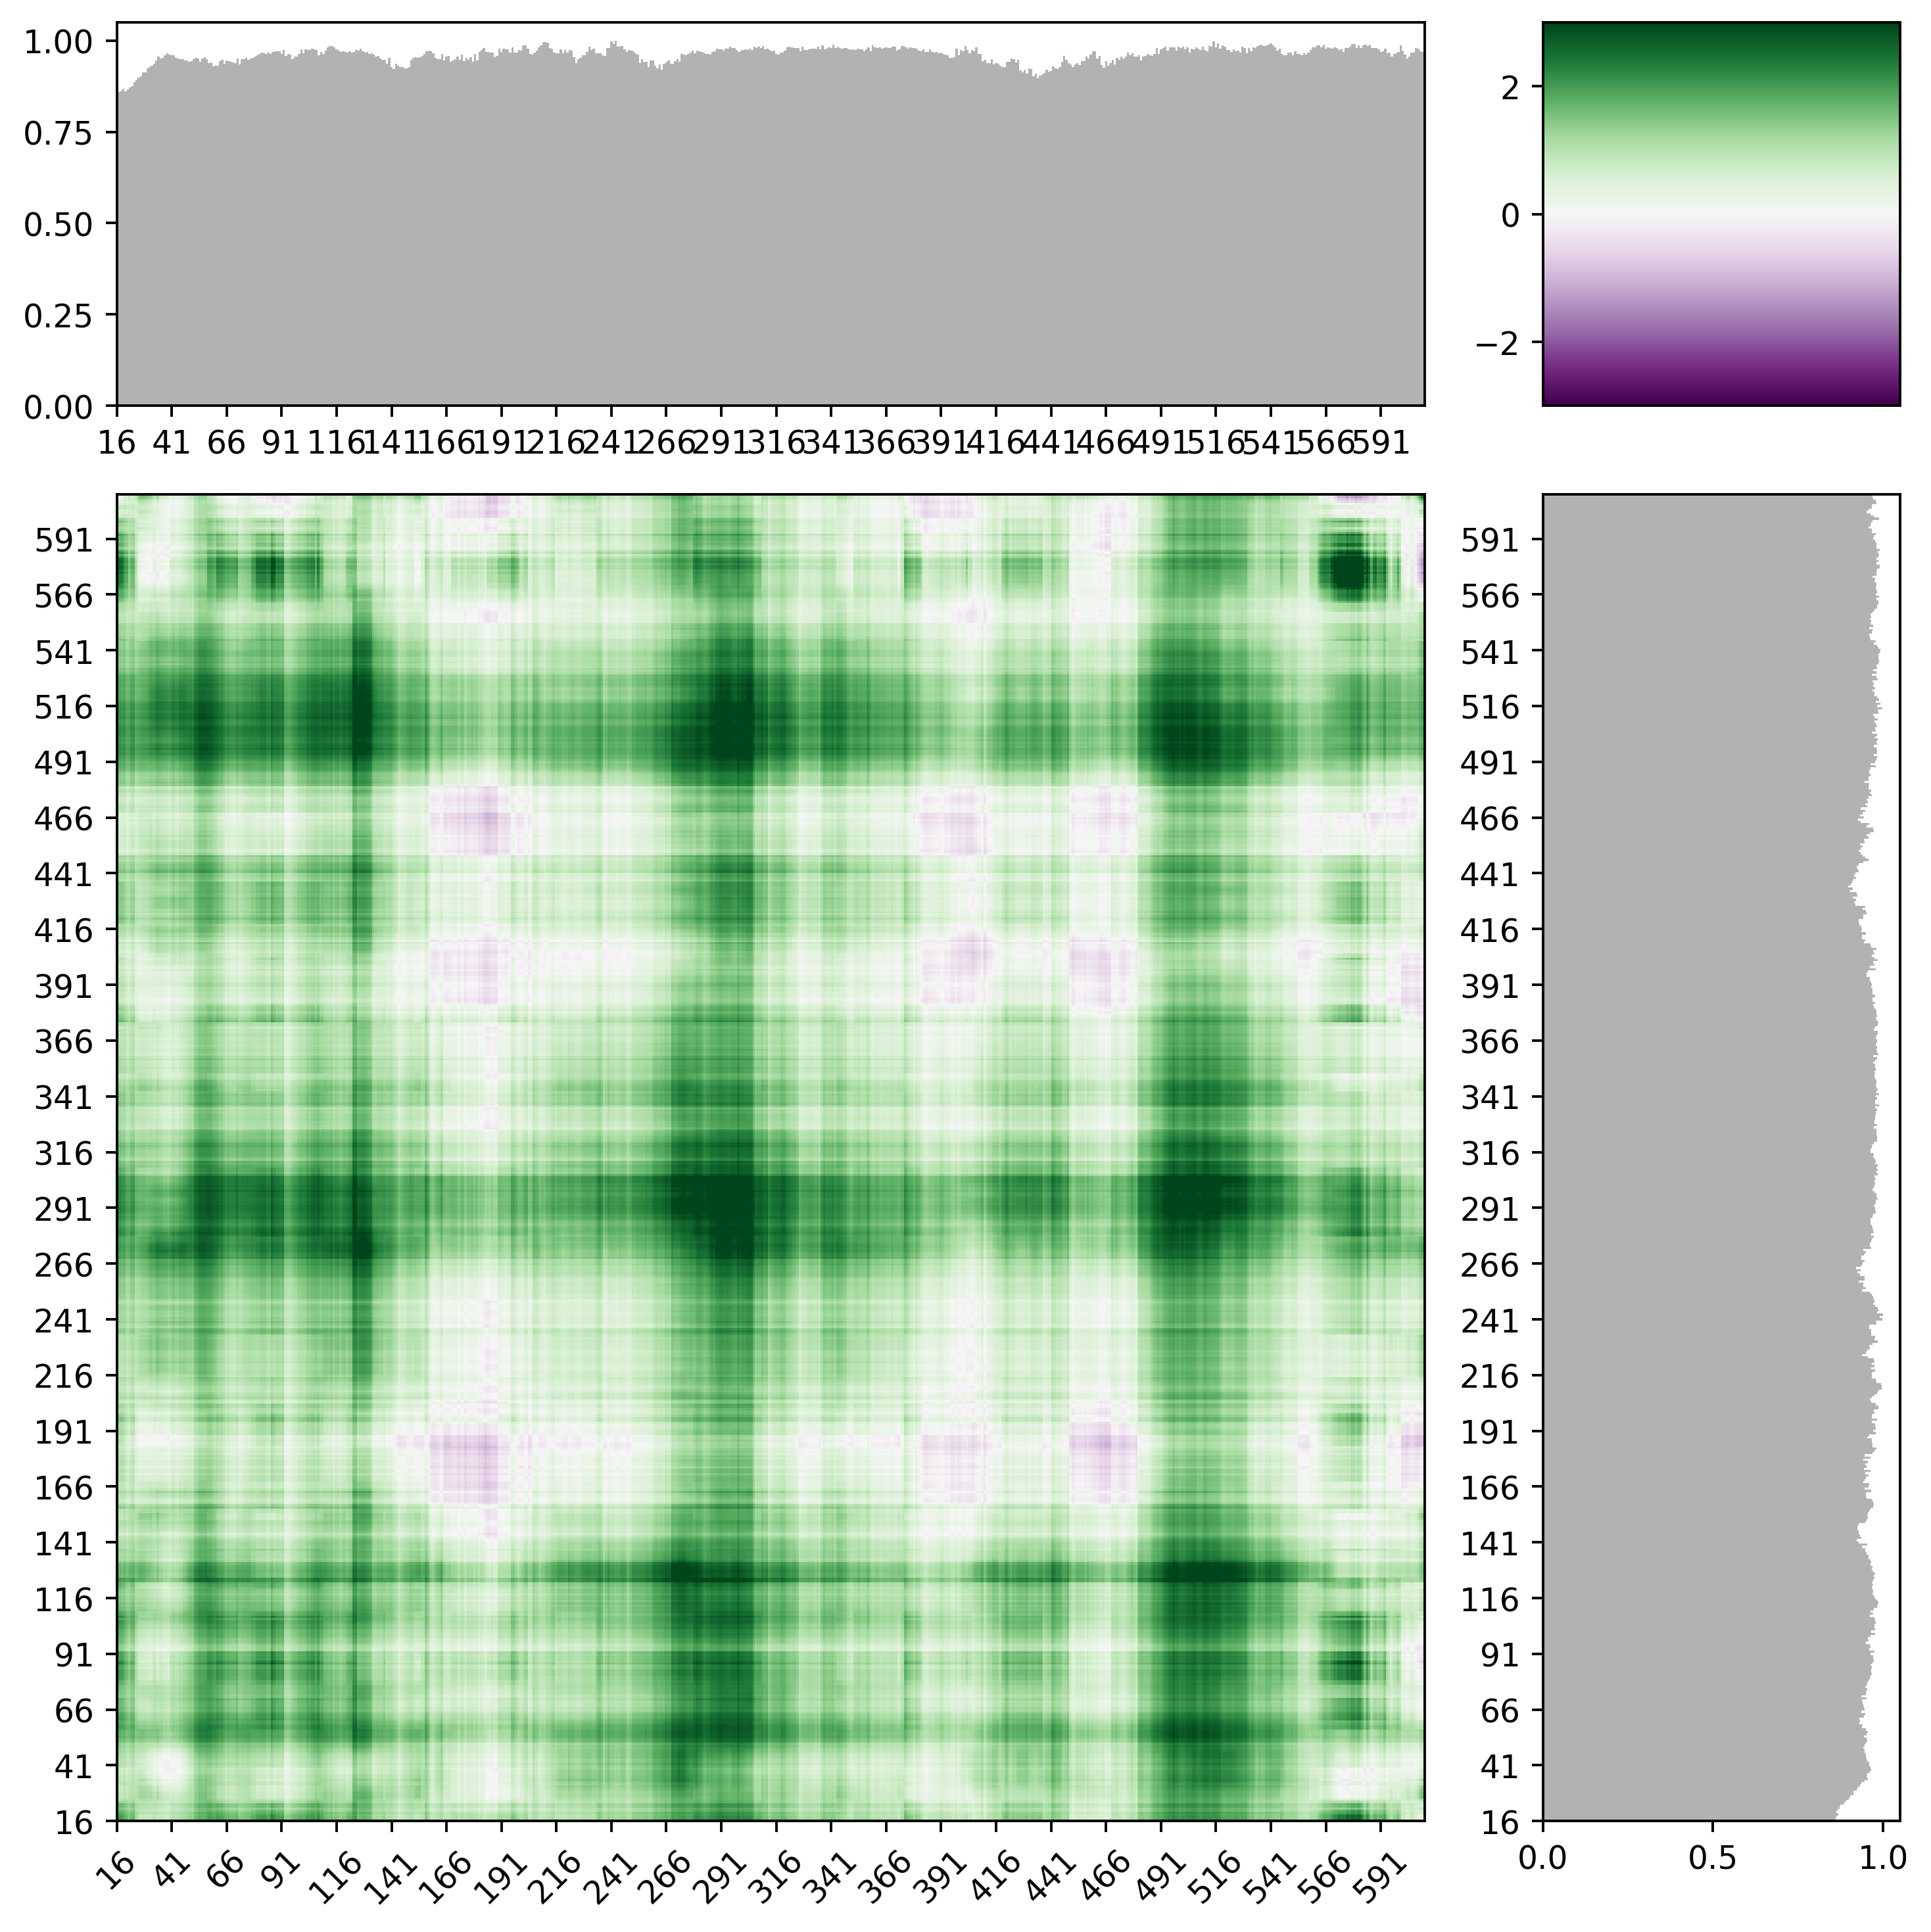

In [4]:

from finches import Mpipi_frontend, CALVADOS_frontend

# Initialize FINCHES
mf = Mpipi_frontend(salt=0.15)
cf = CALVADOS_frontend(salt=0.15)

# Generate baseline Mpipi intermap
mf.interaction_figure(
    sp1_idr,
    sp1_idr,
    window_size=31,
    use_charge_weighting=True,
    use_aliphatic_weighting=True,
    tic_frequency=25,
    zero_folded=True
)


Salt: 0.05 M | Epsilon: 22.94972648617663
Salt: 0.15 M | Epsilon: 23.2306316175152
Salt: 0.3 M | Epsilon: 23.363989433559986
Salt: 0.5 M | Epsilon: 23.42977072888909


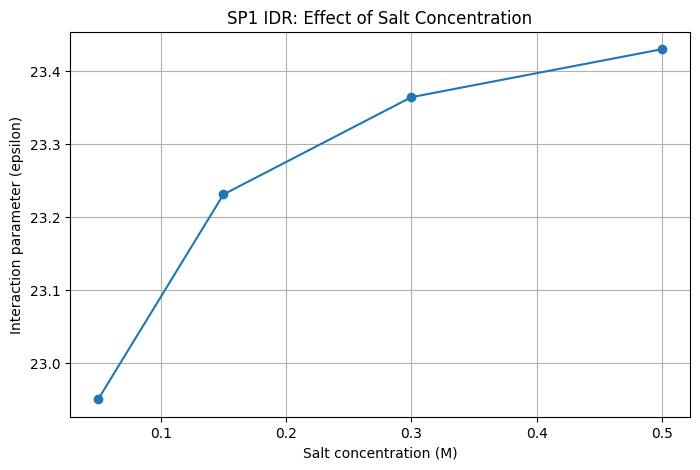

In [5]:

import matplotlib.pyplot as plt

salt_values = [0.05, 0.15, 0.30, 0.50]

results = []

for salt in salt_values:

    model = Mpipi_frontend(salt=salt)

    epsilon = model.epsilon(
        sp1_idr,
        sp1_idr
    )

    results.append(epsilon)

    print(f"Salt: {salt} M | Epsilon: {epsilon}")

# Plot results
plt.figure(figsize=(8, 5))

plt.plot(
    salt_values,
    results,
    marker="o"
)

plt.xlabel("Salt concentration (M)")
plt.ylabel("Interaction parameter (epsilon)")
plt.title("SP1 IDR: Effect of Salt Concentration")

plt.grid(True)
plt.show()


SALT CONCENTRATIONS

SP1 interaction map at 0.05 M salt
SP1 interaction map at 0.15 M salt
SP1 interaction map at 0.3 M salt
SP1 interaction map at 0.5 M salt


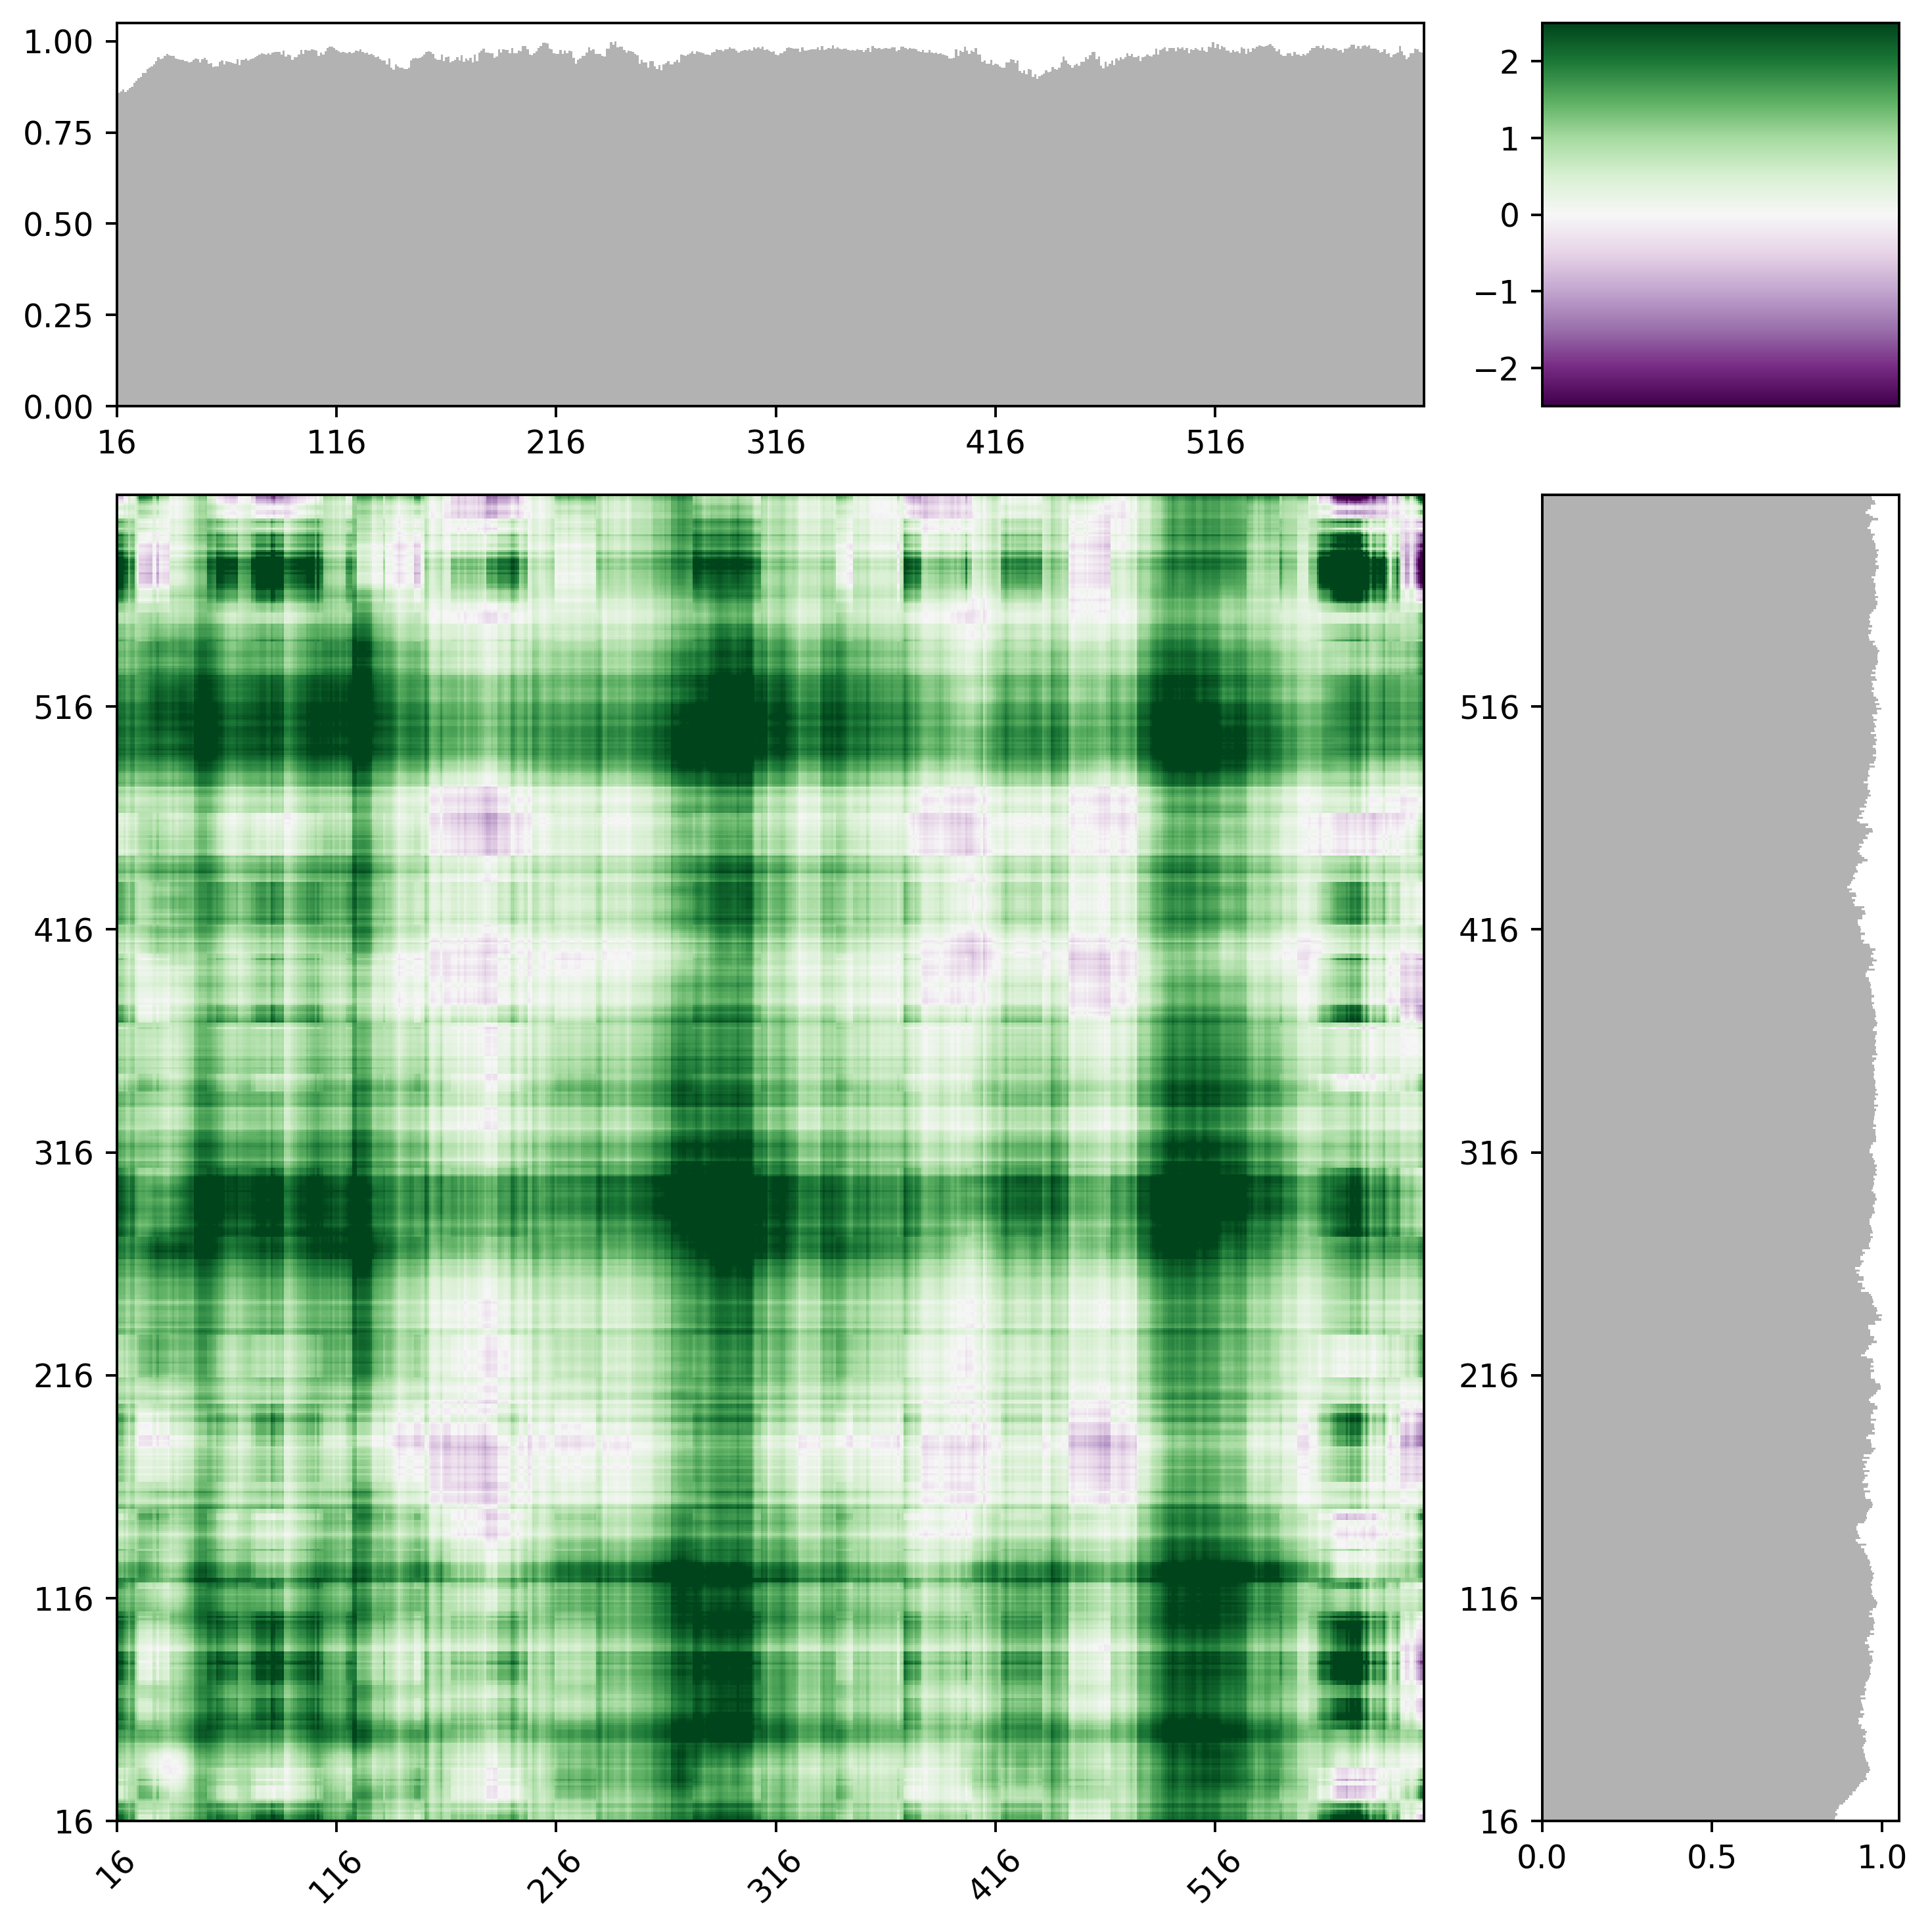

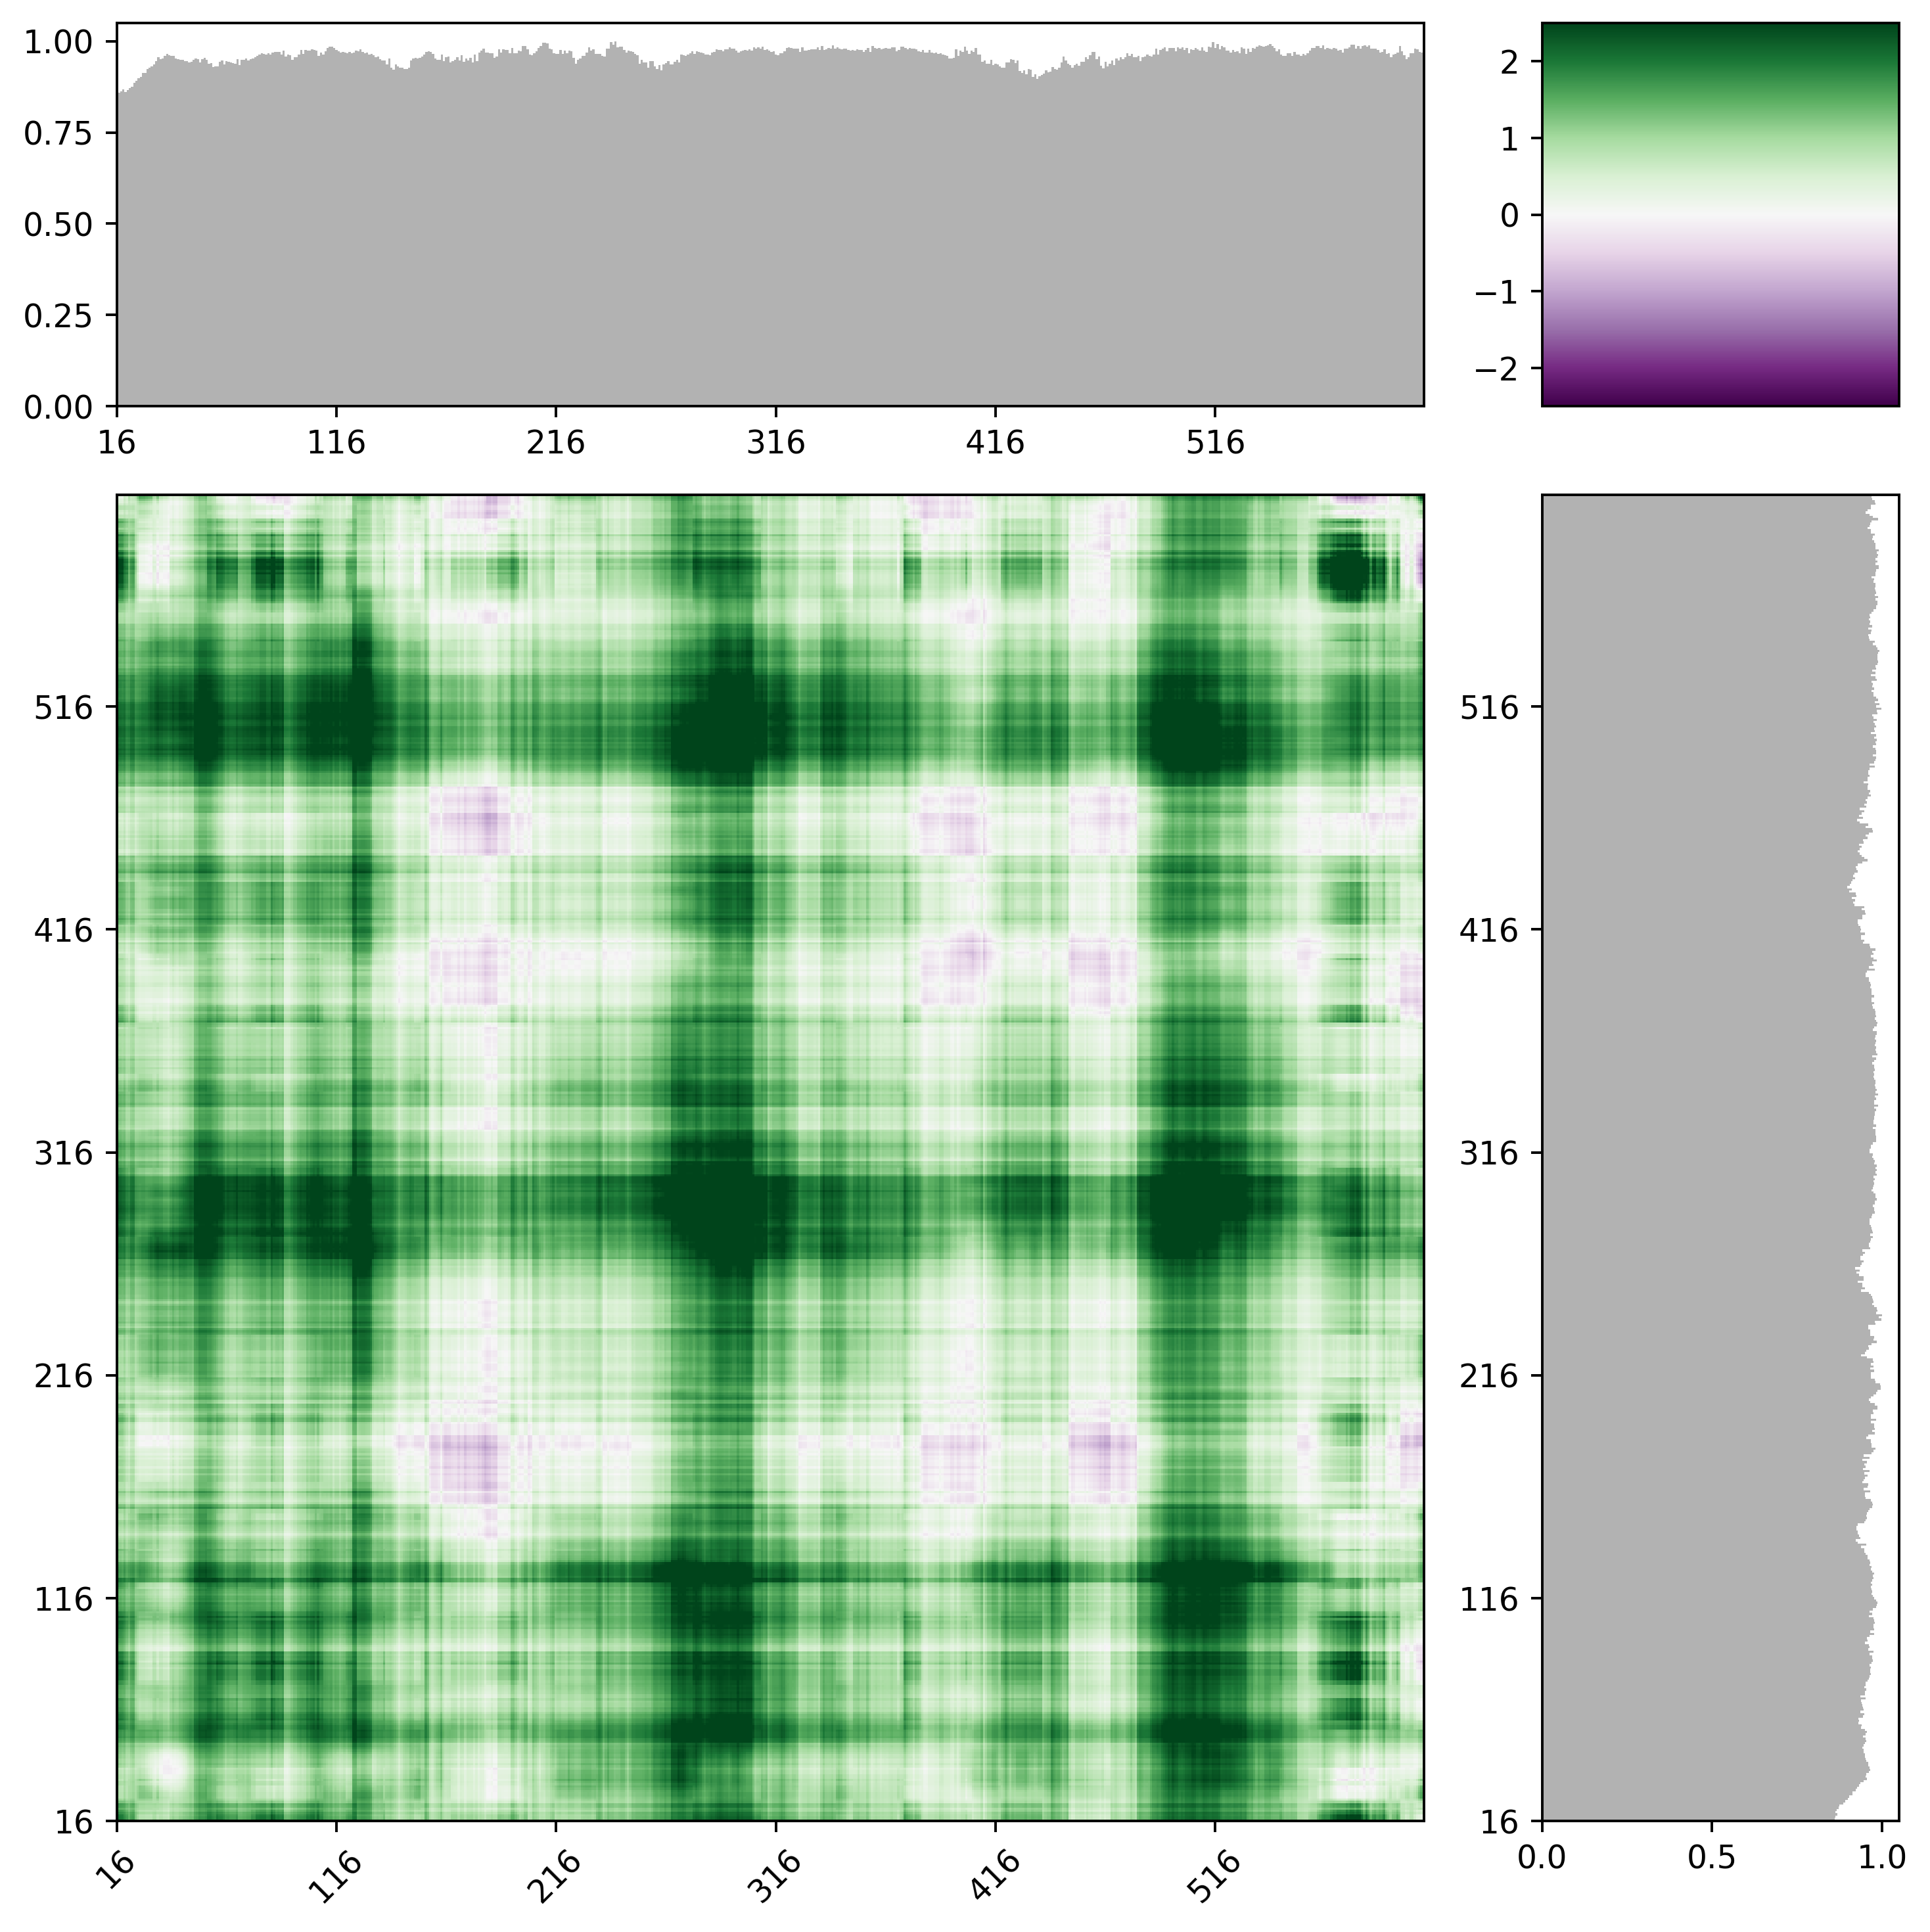

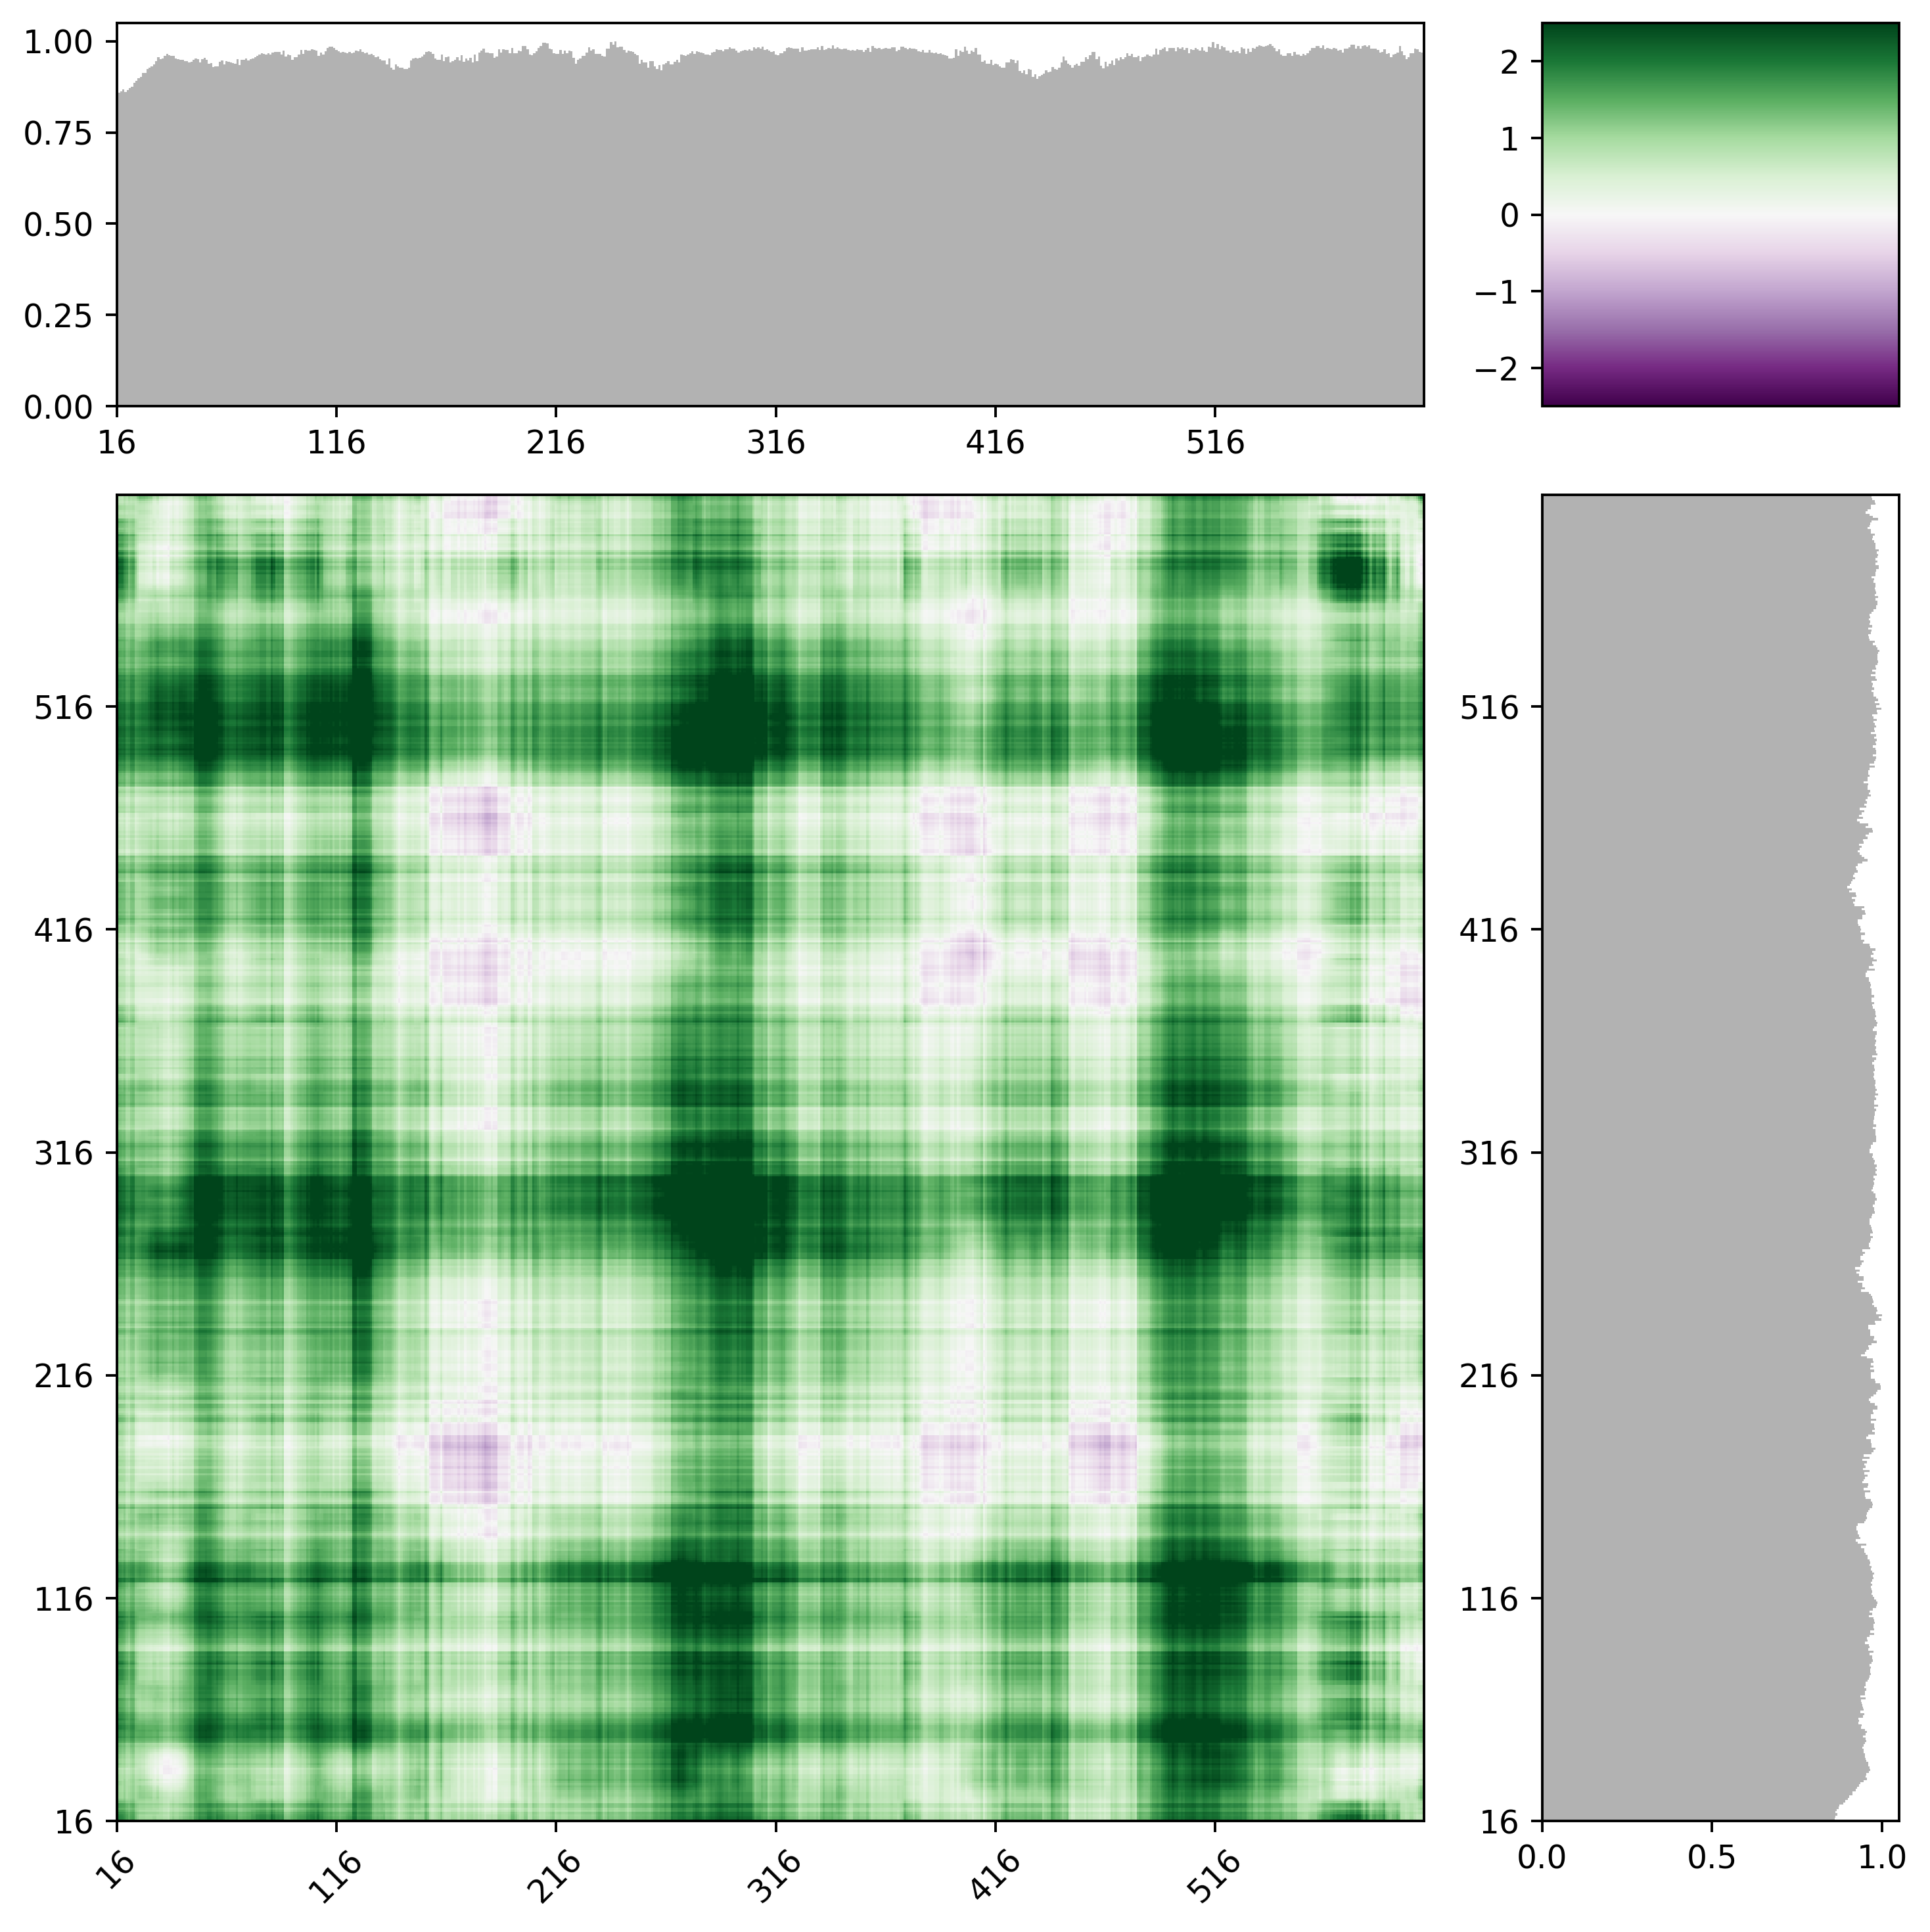

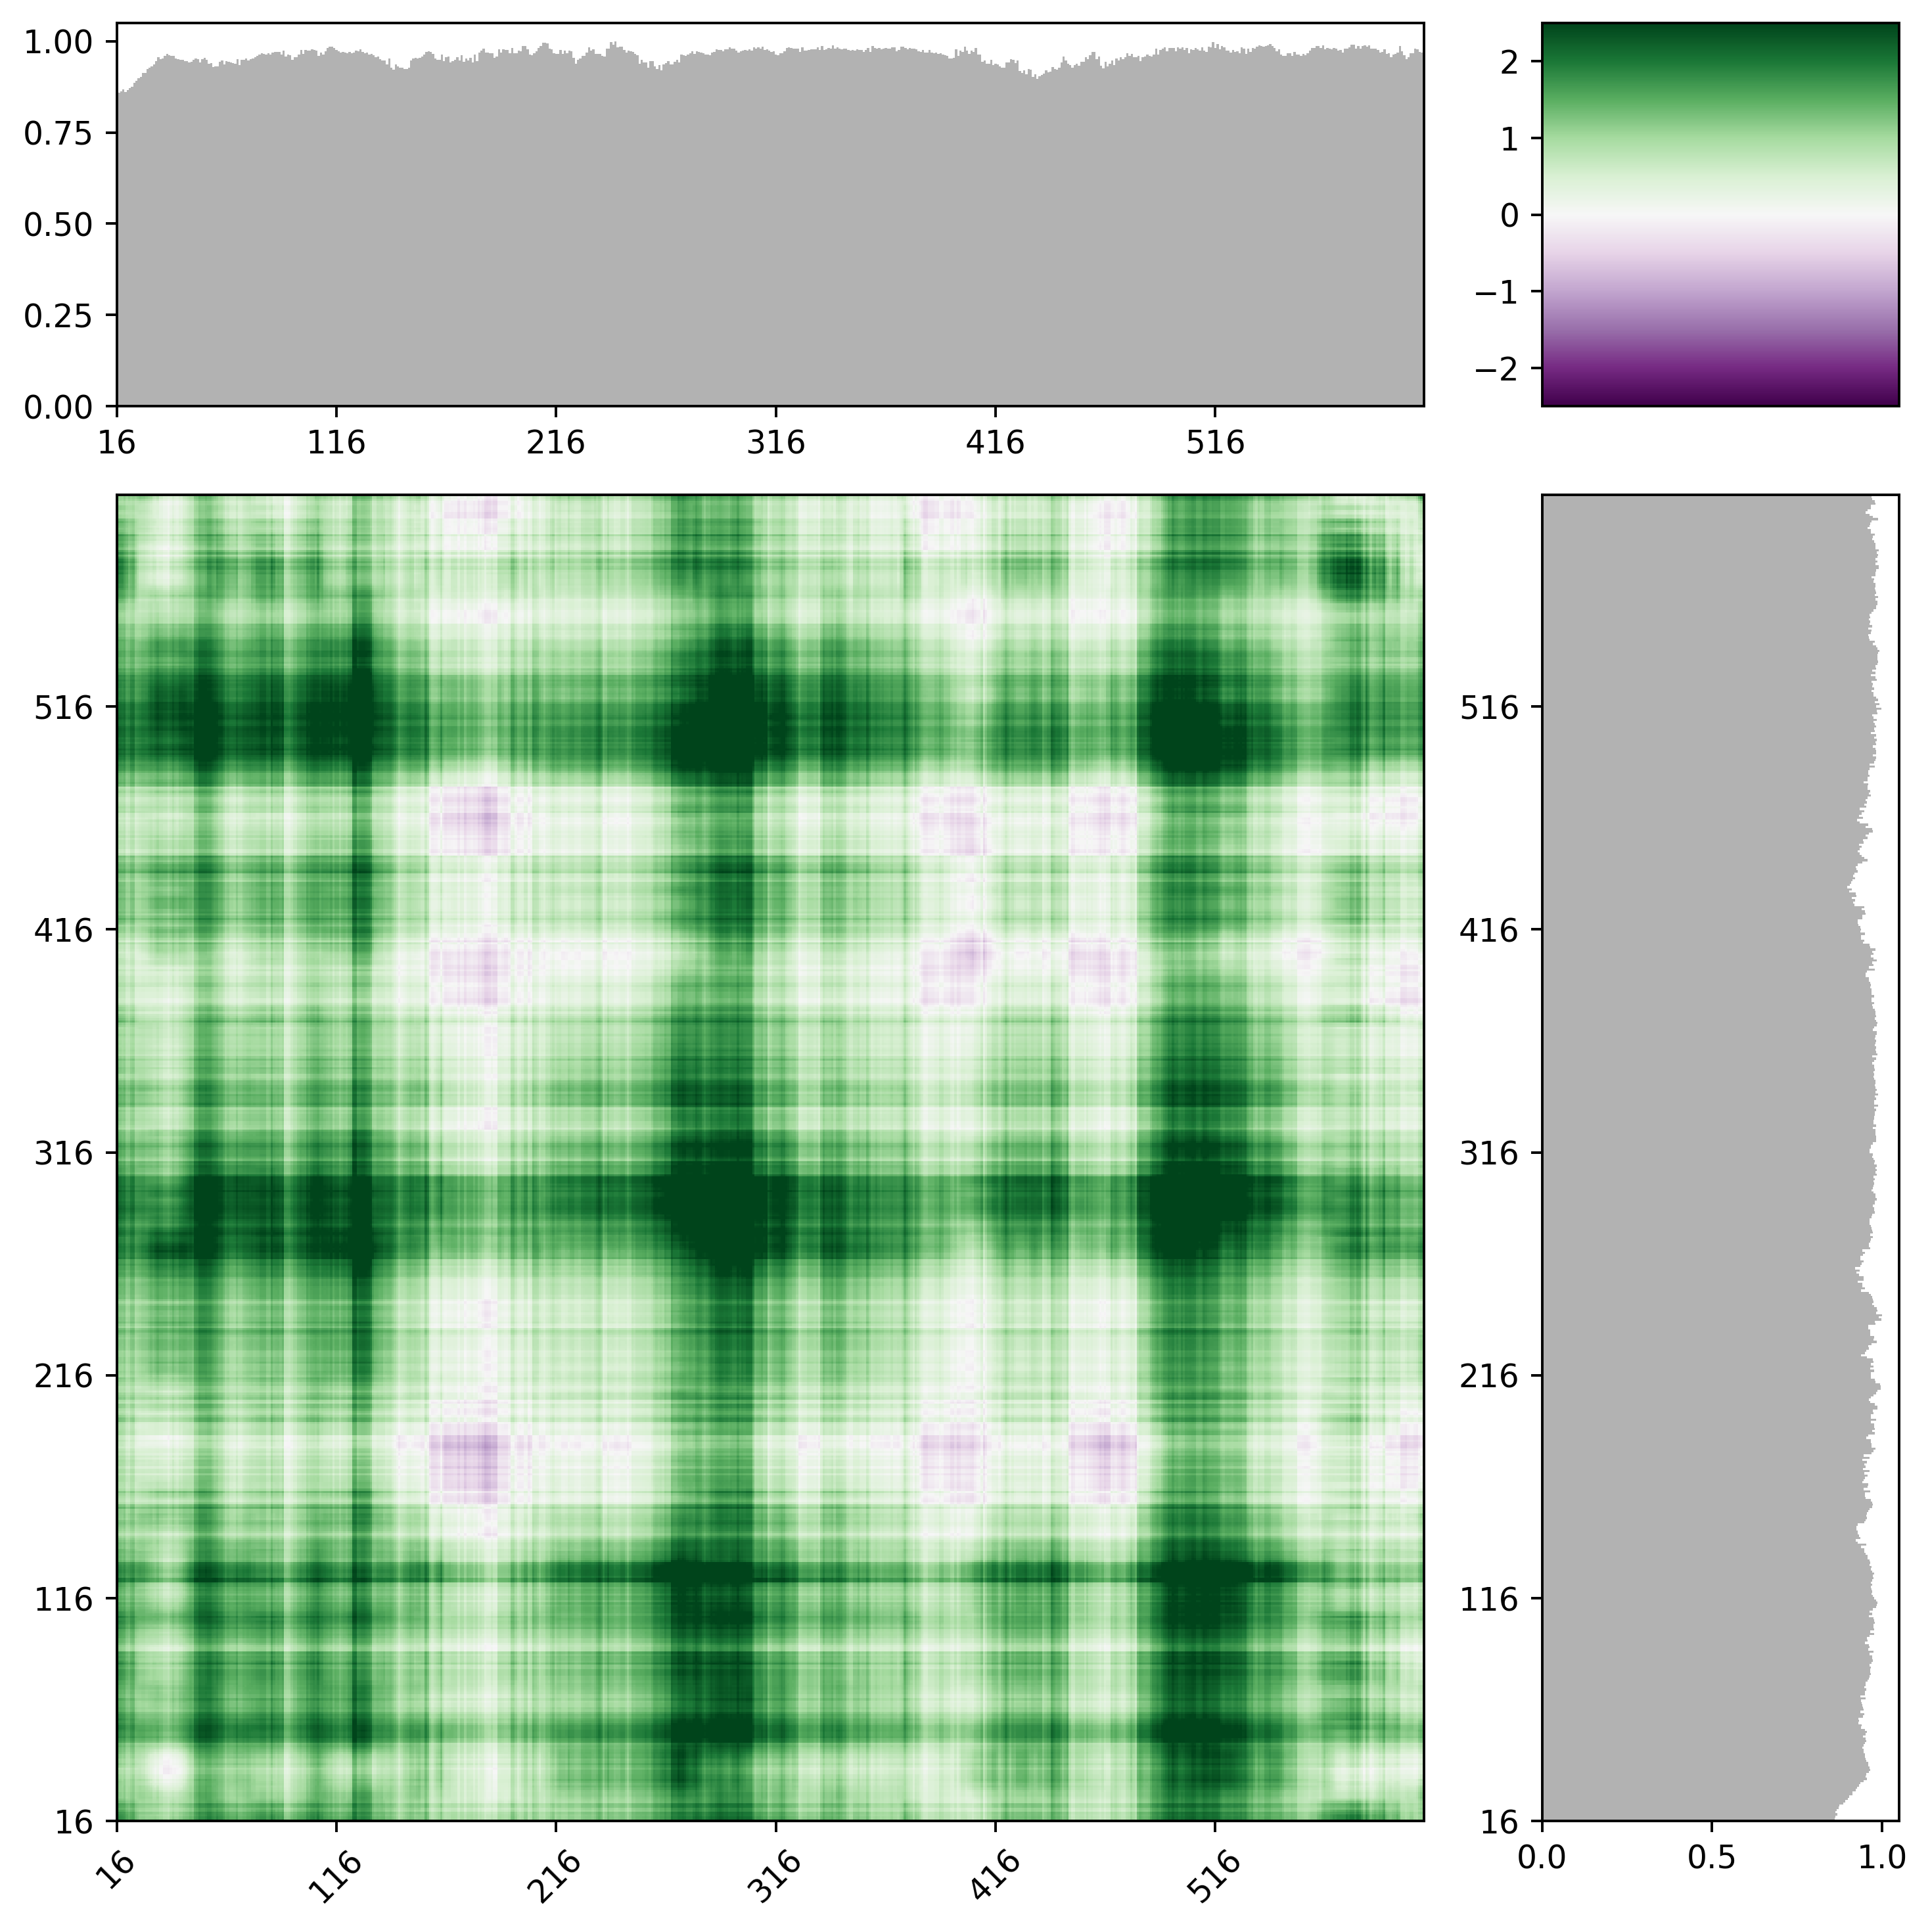

In [6]:

for salt in salt_values:

    model = Mpipi_frontend(salt=salt)

    print(f"SP1 interaction map at {salt} M salt")

    model.interaction_figure(
        sp1_idr,
        sp1_idr,
        window_size=31,
        tic_frequency=100,
        use_charge_weighting=True,
        use_aliphatic_weighting=True,
        zero_folded=True,
        vmin=-2.5,
        vmax=2.5
    )


In [7]:

conditions = {
    "Default": {
        "use_charge_weighting": True,
        "use_aliphatic_weighting": True
    },

    "No charge weighting": {
        "use_charge_weighting": False,
        "use_aliphatic_weighting": True
    },

    "No aliphatic weighting": {
        "use_charge_weighting": True,
        "use_aliphatic_weighting": False
    },

    "Neither weighting": {
        "use_charge_weighting": False,
        "use_aliphatic_weighting": False
    }
}

for name, params in conditions.items():

    epsilon = mf.epsilon(
        sp1_idr,
        sp1_idr,
        **params
    )

    print(f"{name}: {epsilon}")


Default: 23.2306316175152
No charge weighting: 23.897699736993303
No aliphatic weighting: 27.879114534734235
Neither weighting: 28.54618265421233


In [8]:

from collections import Counter

aa_counts = Counter(sp1_idr)

for aa, count in sorted(aa_counts.items()):
    print(
        f"{aa}: {count} "
        f"({count/len(sp1_idr)*100:.2f}%)"
    )


A: 53 (8.48%)
C: 4 (0.64%)
D: 14 (2.24%)
E: 17 (2.72%)
F: 7 (1.12%)
G: 80 (12.80%)
H: 5 (0.80%)
I: 32 (5.12%)
K: 9 (1.44%)
L: 45 (7.20%)
M: 9 (1.44%)
N: 43 (6.88%)
P: 35 (5.60%)
Q: 84 (13.44%)
R: 11 (1.76%)
S: 83 (13.28%)
T: 56 (8.96%)
V: 31 (4.96%)
W: 2 (0.32%)
Y: 5 (0.80%)


In [9]:
print("SP1 full sequence length:", len(sp1_sequence))
print("Sequence analyzed:", len(sp1_idr))

SP1 full sequence length: 785
Sequence analyzed: 625


In [10]:
import numpy as np

salt_values = [0.05, 0.15, 0.30, 0.50]

results = []

for salt in salt_values:
    model = Mpipi_frontend(salt=salt)

    matrix_data = model.intermolecular_idr_matrix(
        sp1_idr,
        sp1_idr,
        window_size=31,
        use_charge_weighting=True,
        use_aliphatic_weighting=True
    )

    matrix = matrix_data[0][0]

    results.append({
        "Salt (M)": salt,
        "Mean interaction": np.mean(matrix),
        "Minimum": np.min(matrix),
        "Maximum": np.max(matrix)
    })

import pandas as pd
pd.DataFrame(results)

,Salt (M),Mean interaction,Minimum,Maximum
0,0.05,1.114240,-3.585264,6.335564
1,0.15,1.120332,-1.369478,4.395930
2,0.30,1.122821,-1.152488,3.438818
3,0.50,1.123803,-1.170322,3.438818
